In [1]:
import os
import torch
import pandas as pd
import scanpy as sc
from sklearn import metrics
import multiprocessing as mp
from STWaveGraph.STWaveGraph import STWaveGraph
import matplotlib.pyplot as plt

In [ ]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
import rpy2

In [3]:
dataset = 'Human_Breast_Cancer'
n_clusters = 20
file_fold = '/root/workspace/STWaveGraph-main/Data/' + str(dataset) #please replace 'file_fold' with the download path
adata = sc.read_visium(file_fold, count_file='filtered_feature_bc_matrix.h5', load_images=True)
adata.var_names_make_unique()

/opt/conda/envs/SpatioFrep/lib/python3.8/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [4]:
import torch
print("PyTorch版本:", torch.__version__)
print("CUDA是否可用:", torch.cuda.is_available())

PyTorch版本: 2.4.1+cu124
CUDA是否可用: True


73:600:3500:random seed: 6497
6382:0.671
76:seed: 5549:0.603
510:seed: 8951:0.516

In [5]:
model = STWaveGraph(
    adata=adata,
    n_clusters=n_clusters,
    device=device,

    n_top_genes=3000,
    pca_dim=50,
    n_neighbors_spatial=6,
    expr_power=1.3,

    hidden_dim=128,
    proj_dim=64,
    n_bands=3,
    spectral_k=128,
    spectral_low_ratio=0.72,

    pretrain_epochs=250,
    finetune_epochs=220,

    lambda_rec=0.30,
    lambda_ssl=0.35,
    lambda_smooth=0.020,
    lambda_kl=0.8,
    lambda_balance=0.0,
    lambda_boundary=0.20,
    boundary_margin=1.0,

    cluster_method="mclust",
    cluster_pca_dim=24,
    mclust_model="VVE",
    refine_iters=1,

    random_seed=2024
)
adata = model.train(verbose=True)

========== Stage 1: Representation Pretraining ==========


100%|██████████| 250/250 [00:22<00:00, 11.07it/s]


========== Initialize Cluster Centers ==========
========== Stage 2: Clustering Finetuning ==========


 24%|██▎       | 52/220 [00:04<00:15, 10.79it/s]

[Finetune] Epoch 50/220 | loss=0.7000 | rec=1.6594 | ssl=0.3391 | smooth=0.3519 | kl=0.0378 | balance=0.0010 | bd=0.2299 | extra_reg_on=1


...

 92%|█████████▏| 202/220 [00:18<00:01, 11.21it/s]

[Finetune] Epoch 200/220 | loss=0.5286 | rec=1.3135 | ssl=0.1238 | smooth=0.4052 | kl=0.0538 | balance=0.0006 | bd=0.1992 | extra_reg_on=1


100%|██████████| 220/220 [00:20<00:00, 10.87it/s]


fitting ...
  |======================================================================| 100%


/root/workspace/STWaveGraph-main/STWaveGraph/utils.py:308: RuntimeWarning: [cluster_embedding] mclust failed: AttributeError("'NULLType' object has no attribute 'rx2'"). Fallback to sklearn GaussianMixture.
  warnings.warn(


In [7]:
# add ground_truth
df_meta = pd.read_csv(file_fold + '/metadata.tsv', sep='\t')
df_meta_layer = df_meta['ground_truth']
adata.obs['ground_truth'] = df_meta_layer.values

In [8]:
adata

AnnData object with n_obs × n_vars = 3798 × 36601
    obs: 'in_tissue', 'array_row', 'array_col', 'pred_domain_raw', 'pred_domain', 'ground_truth'
    var: 'gene_ids', 'feature_types', 'genome', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'spatial', 'hvg', 'log1p', 'cluster_method_used', 'cluster_pca_dim', 'mclust_model', 'regularization_warmup_epochs'
    obsm: 'spatial', 'emb', 'model_q', 'soft_assign'

In [10]:
adata.obsm['emb']

array([[-0.08019411, -0.0840859 ,  0.00545507, ..., -0.11061316,
        -0.11046723, -0.02296687],
       [ 0.01582547, -0.00051455,  0.06387   , ..., -0.03591573,
        -0.0787778 , -0.05512899],
       [-0.10327772, -0.10560208,  0.13996263, ..., -0.04439038,
        -0.09626471, -0.04981464],
       ...,
       [-0.00254395, -0.01210646,  0.05187643, ..., -0.05957723,
         0.02694479, -0.05440624],
       [-0.10456757, -0.05823611, -0.0538798 , ..., -0.06112433,
        -0.0926711 , -0.10299227],
       [-0.02304847, -0.02074827, -0.11164757, ..., -0.00895413,
         0.20989002,  0.03264441]], dtype=float32)

In [11]:
# filter out NA nodes
adata = adata[~pd.isnull(adata.obs['ground_truth'])]

# calculate metric ARI
ARI = metrics.adjusted_rand_score(adata.obs['pred_domain'], adata.obs['ground_truth'])
adata.uns['ARI'] = ARI

print('Dataset:', dataset)
print('ARI:', ARI)

/opt/conda/envs/SpatioFrep/lib/python3.8/site-packages/anndata/compat/_overloaded_dict.py:106: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  self.data[key] = value


Dataset: Human_Breast_Cancer
ARI: 0.6226357865192154


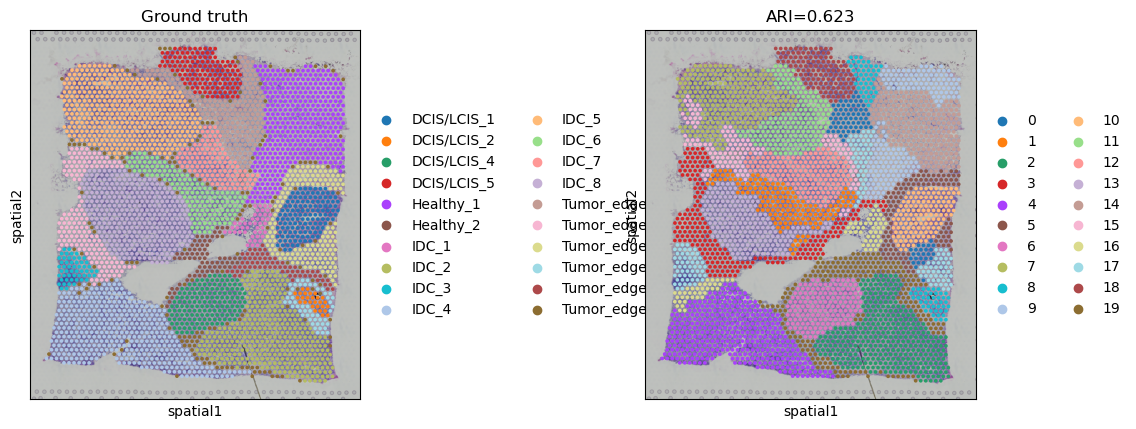

In [12]:
sc.pl.spatial(
    adata,
    img_key="hires",
    color=["ground_truth", "pred_domain"],
    title=["Ground truth", f"ARI={ARI:.3f}"],
    spot_size=200,
    show=True
)
